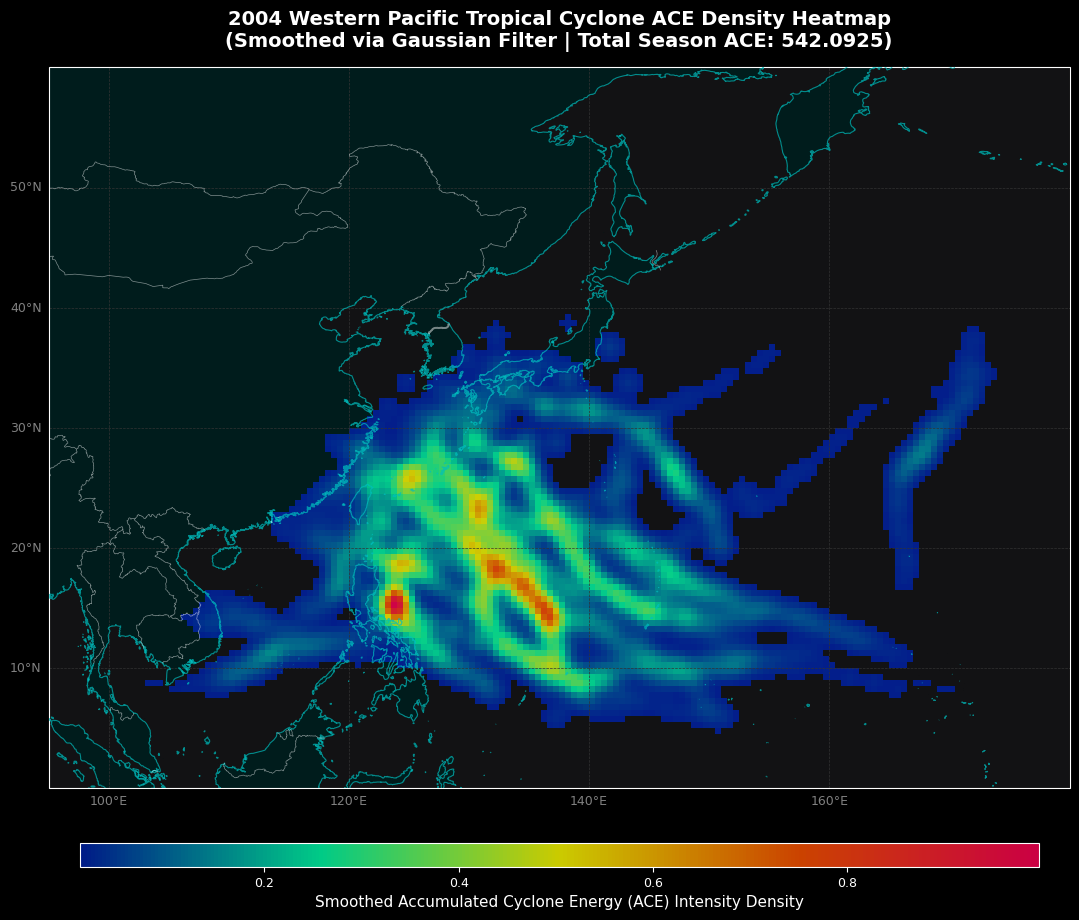

In [32]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import urllib3
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.style as mplstyle
from scipy.ndimage import gaussian_filter  # <-- Added for smoothing

# Setup background style
mplstyle.use("dark_background") 
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
http = urllib3.PoolManager(cert_reqs='CERT_NONE', assert_hostname=False)

def fetch_url(urlLink):
    response = http.request('GET', urlLink)
    return response.data.decode('utf-8')

def parse_data(html_content):
    soup = BeautifulSoup(html_content, 'html.parser')
    return soup.get_text()

# Fetch data

#https://gist.githubusercontent.com/Sohum09/cf09c0accef93689a452354648c6ab76/raw/dc15b1777143358dbd7d80ce262ce8886d76433f/2013_WPAC_Final.txt
#https://gist.githubusercontent.com/hydrangea72/320ed6019712ced9c2ba50c68cde7ae0/raw/0bc8230bc8bd3bc6b88d639fd12b95476b4be950/2004WPAC.txt
url = "https://gist.githubusercontent.com/hydrangea72/320ed6019712ced9c2ba50c68cde7ae0/raw/0bc8230bc8bd3bc6b88d639fd12b95476b4be950/2004WPAC.txt"
btk_data = fetch_url(url)
parsed_data = parse_data(btk_data)
lines = parsed_data.split('\n')

# Storage arrays
cdx, cdy, ace_values = [], [], []

for line in lines:
    if line.strip():
        stormData = line.split(',')
        
        # 1. Parse coordinates
        lon_str = stormData[7].strip()
        lat_str = stormData[6].strip()
        
        if lon_str[-1] == 'W':
            lon = (float(lon_str[:-1].strip()) / 10) * -1
        else:
            lon = float(lon_str[:-1].strip()) / 10
            
        if lat_str[-1] == 'S':
            lat = (float(lat_str[:-1].strip()) / 10) * -1
        else:
            lat = float(lat_str[:-1].strip()) / 10

        # 2. Extract filtering parameters
        wind = int(stormData[8].strip()) if stormData[8].strip() != ' ' else 0
        status = stormData[10].strip()
        time_check = int(stormData[2].strip()[-2:])

        # 3. Calculate ACE point-by-point
        if time_check % 6 == 0 and wind >= 34 and status not in ['DB', 'LO', 'WV', 'EX', 'IN']:
            pt_ace = (wind ** 2) / 10000
        else:
            pt_ace = 0.0

        if pt_ace > 0:
            cdx.append(lon)
            cdy.append(lat)
            ace_values.append(pt_ace)

# --- SPATIAL BINNING ---
lon_min, lon_max = 95.0, 180.0
lat_min, lat_max = 0.0, 60.0
grid_size = 0.5  

# Create bin edges
lon_bins = np.arange(lon_min, lon_max + grid_size, grid_size)
lat_bins = np.arange(lat_min, lat_max + grid_size, grid_size)

# Compute 2D histogram
ace_grid, xedges, yedges = np.histogram2d(
    cdx, cdy, 
    bins=[lon_bins, lat_bins], 
    weights=ace_values
)
ace_grid = ace_grid.T

# --- GAUSSIAN SMOOTHING ---
smoothed_ace = gaussian_filter(ace_grid, sigma=1.5)
smoothed_ace = np.ma.masked_where(smoothed_ace < 0.01, smoothed_ace)

# --- PLOTTING ---
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(14, 10))
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

from matplotlib import colors
res = '10m'
ax.add_feature(cfeature.LAND.with_scale(res), facecolor=colors.to_rgba("c", 0.15), zorder=1)
ax.add_feature(cfeature.OCEAN.with_scale(res), facecolor='#121214', zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale(res), linewidth=0.8, edgecolor="c", alpha=0.7, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale(res), edgecolor="w", linewidth=0.5, alpha=0.5, zorder=3)

cmap = mcolors.LinearSegmentedColormap.from_list(
    "ace_smooth", ["#0022aa", "#00ffaa", "#ffff00", "#ff5500", "#ff0055"]
)
cmap.set_bad(alpha=0)

mesh = ax.pcolormesh(xedges, yedges, smoothed_ace, cmap=cmap, transform=ccrs.PlateCarree(), zorder=2, alpha=0.8)

cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.06, shrink=0.7, aspect=40)
cbar.set_label('Smoothed Accumulated Cyclone Energy (ACE) Intensity Density', fontsize=11, color='w')
cbar.ax.tick_params(labelsize=9, labelcolor='w')

# Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='#333333', zorder=4)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'color': 'gray', 'size': 9}
gl.ylabel_style = {'color': 'gray', 'size': 9}

total_season_ace = sum(ace_values)
plt.title(f"2004 Western Pacific Tropical Cyclone ACE Density Heatmap\n(Smoothed via Gaussian Filter | Total Season ACE: {total_season_ace:.4f})", 
          fontsize=14, pad=15, weight='bold', color='w')

plt.tight_layout()
plt.show()

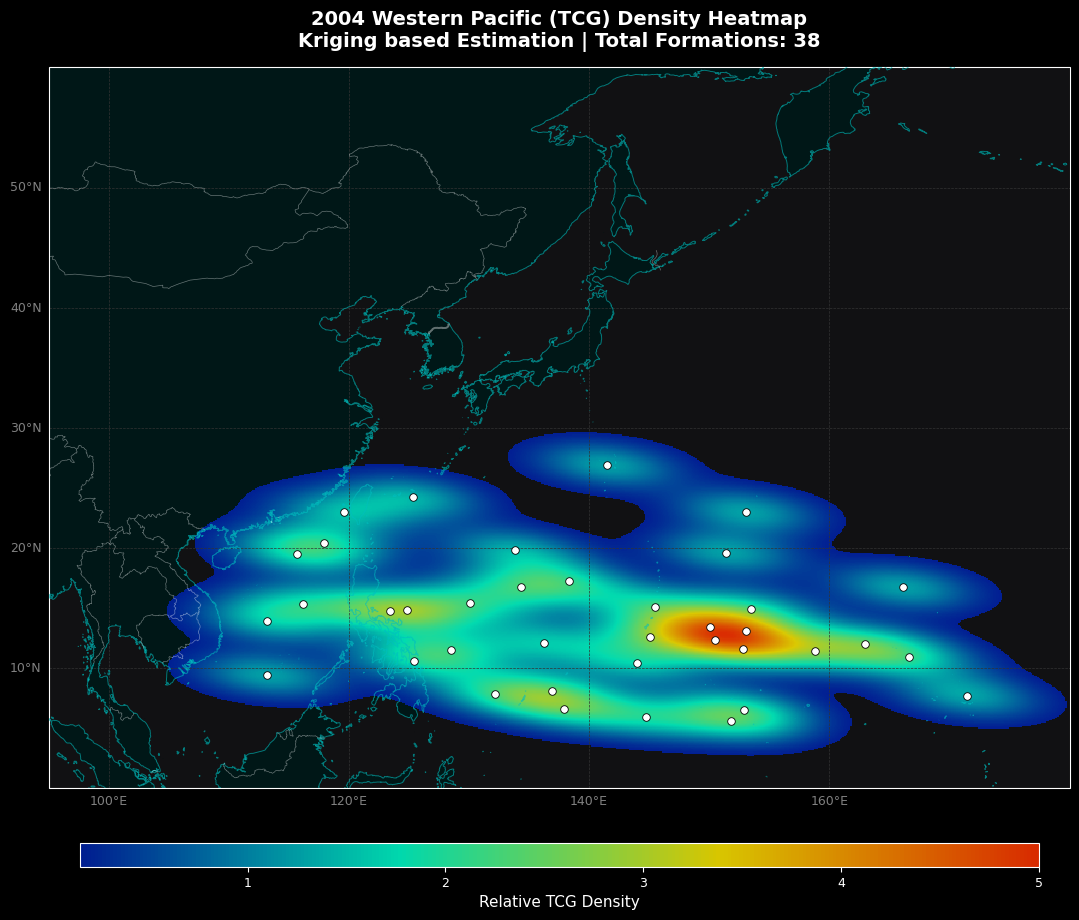

In [9]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import urllib3
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.style as mplstyle
from scipy.stats import gaussian_kde  # <-- Added for continuous point density

# Setup background style
mplstyle.use("dark_background") 
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
http = urllib3.PoolManager(cert_reqs='CERT_NONE', assert_hostname=False)

def fetch_url(urlLink):
    response = http.request('GET', urlLink)
    return response.data.decode('utf-8')

def parse_data(html_content):
    soup = BeautifulSoup(html_content, 'html.parser')
    return soup.get_text()

# Fetch and Parse Data
url = "https://gist.githubusercontent.com/hydrangea72/320ed6019712ced9c2ba50c68cde7ae0/raw/0bc8230bc8bd3bc6b88d639fd12b95476b4be950/2004WPAC.txt"
btk_data = fetch_url(url)
parsed_data = parse_data(btk_data)
lines = parsed_data.split('\n')

tcg_lon, tcg_lat = [], []
current_storm_id = None
found_tcg_for_current_storm = False

for line in lines:
    if line.strip():
        stormData = line.split(',')
        storm_id = stormData[1].strip()
        status = stormData[10].strip()

        if storm_id != current_storm_id:
            current_storm_id = storm_id
            found_tcg_for_current_storm = False 

        if not found_tcg_for_current_storm and status in ['TD', 'TS']:
            lon_str = stormData[7].strip()
            lon = (float(lon_str[:-1].strip()) / 10) * -1 if lon_str[-1] == 'W' else float(lon_str[:-1].strip()) / 10
            lat_str = stormData[6].strip()
            lat = (float(lat_str[:-1].strip()) / 10) * -1 if lat_str[-1] == 'S' else float(lat_str[:-1].strip()) / 10

            tcg_lon.append(lon)
            tcg_lat.append(lat)
            found_tcg_for_current_storm = True

# --- MAP RESOLUTION & GRID CONFIGURATION ---
lon_min, lon_max = 95.0, 180.0
lat_min, lat_max = 0.0, 60.0

# Create a highly detailed underlying mesh grid
fine_res = 0.1
fine_x = np.arange(lon_min, lon_max + fine_res, fine_res)
fine_y = np.arange(lat_min, lat_max + fine_res, fine_res)
fine_X, fine_Y = np.meshgrid(fine_x, fine_y)

# --- CONTINUOUS DENSITY CALCULATION (KDE) ---
positions = np.vstack([fine_X.ravel(), fine_Y.ravel()])
values = np.vstack([tcg_lon, tcg_lat])

# gaussian_kde calculates the continuous density surface directly from coordinates
kernel = gaussian_kde(values, bw_method=0.25) # Lower bw_method = tighter hotspots
Z = np.reshape(kernel(positions).T, fine_X.shape)

# Normalize Z to look like a count weighting factor
Z = (Z - Z.min()) / (Z.max() - Z.min()) * 5.0 

# Mask out trace values so background remains dark
Z = np.ma.masked_where(Z < 0.15, Z)

# --- PLOTTING ---
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(14, 10))
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

res = '10m'
ax.add_feature(cfeature.LAND.with_scale(res), facecolor=colors.to_rgba("c", 0.12), zorder=1)
ax.add_feature(cfeature.OCEAN.with_scale(res), facecolor='#111113', zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale(res), linewidth=0.7, edgecolor="c", alpha=0.6, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale(res), edgecolor="w", linewidth=0.5, alpha=0.4, zorder=3)

cmap = mcolors.LinearSegmentedColormap.from_list("tcg_kde", ["#0022aa", "#00ffcc", "#ffea00", "#ff3300"])
cmap.set_bad(alpha=0)

# Render using fine_x and fine_y
mesh = ax.pcolormesh(fine_x, fine_y, Z, cmap=cmap, transform=ccrs.PlateCarree(), zorder=2, alpha=0.85, shading='auto')

ax.scatter(tcg_lon, tcg_lat, color='#ffffff', edgecolor='#000000', s=30, linewidth=0.6, transform=ccrs.PlateCarree(), zorder=4, label='Genesis Point')

cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.06, shrink=0.7, aspect=40)
cbar.set_label('Relative TCG Density', fontsize=11, color='w')
cbar.ax.tick_params(labelsize=9, labelcolor='w')

gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='#333333', zorder=5)
gl.top_labels = False; gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER; gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'color': 'gray', 'size': 9}; gl.ylabel_style = {'color': 'gray', 'size': 9}

plt.title(f"2004 Western Pacific (TCG) Density Heatmap\nKriging based Estimation | Total Formations: {len(tcg_lon)}", fontsize=14, pad=15, weight='bold', color='w')
plt.tight_layout()
plt.show()

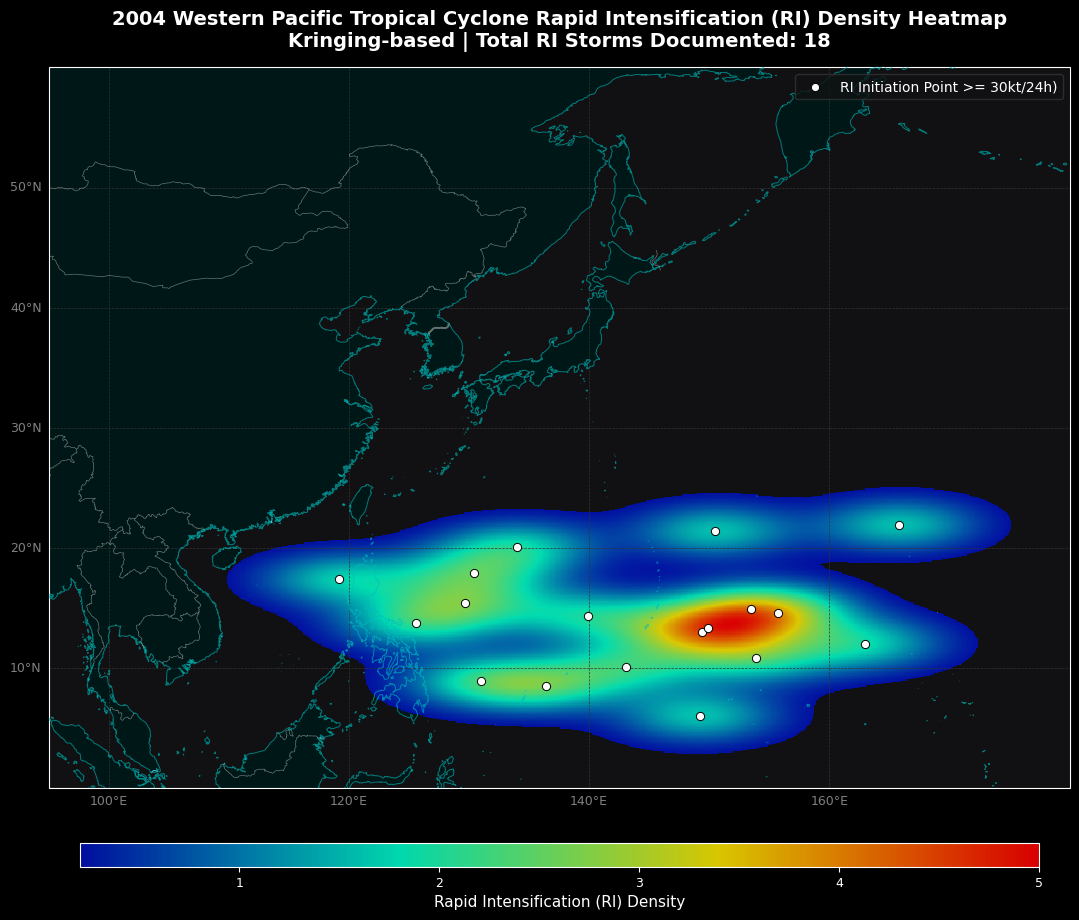

In [34]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import urllib3
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.style as mplstyle
from scipy.stats import gaussian_kde

# Setup background style
mplstyle.use("dark_background") 
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
http = urllib3.PoolManager(cert_reqs='CERT_NONE', assert_hostname=False)

def fetch_url(urlLink):
    response = http.request('GET', urlLink)
    return response.data.decode('utf-8')

def parse_data(html_content):
    soup = BeautifulSoup(html_content, 'html.parser')
    return soup.get_text()

# Fetch and Parse Data
url = "https://gist.githubusercontent.com/hydrangea72/320ed6019712ced9c2ba50c68cde7ae0/raw/0bc8230bc8bd3bc6b88d639fd12b95476b4be950/2004WPAC.txt"
btk_data = fetch_url(url)
parsed_data = parse_data(btk_data)
lines = parsed_data.split('\n')

# 1. First pass: Parse lines into an ordered list from oldest to newest
raw_records = []
for line in lines:
    if line.strip():
        stormData = line.split(',')
        
        # Parse coordinates safely
        lon_str = stormData[7].strip()
        lon = (float(lon_str[:-1].strip()) / 10) * -1 if lon_str[-1] == 'W' else float(lon_str[:-1].strip()) / 10
        lat_str = stormData[6].strip()
        lat = (float(lat_str[:-1].strip()) / 10) * -1 if lat_str[-1] == 'S' else float(lat_str[:-1].strip()) / 10
        
        wind = int(stormData[8].strip()) if stormData[8].strip() != ' ' else 0
        storm_id = stormData[1].strip()
        
        raw_records.append({'id': storm_id, 'lon': lon, 'lat': lat, 'wind': wind})

# Reverse records so the time flow goes forward chronologically

# 2. Group records by unique Storm ID
storms = {}
for record in raw_records:
    s_id = record['id']
    if s_id not in storms:
        storms[s_id] = []
    storms[s_id].append(record)

# 3. Detect the first RI instance per storm
ri_lon, ri_lat = [], []

for s_id, tracks in storms.items():
    # We need at least 5 points to evaluate a 24-hour window (0h, 6h, 12h, 18h, 24h)
    if len(tracks) < 5:
        continue
        
    for i in range(len(tracks) - 4):
        wind_start = tracks[i]['wind']
        wind_end = tracks[i+4]['wind']
        delta_wind = wind_end - wind_start
        
        # Check if 24-hour wind intensification meets or exceeds 30 knots
        if delta_wind >= 30:
            # Capture the start coordinate where the RI window initiated
            ri_lon.append(tracks[i]['lon'])
            ri_lat.append(tracks[i]['lat'])
            break # Break out immediately to ensure we only count the *first* instance per storm

# --- MAP RESOLUTION & GRID CONFIGURATION ---
lon_min, lon_max = 95.0, 180.0
lat_min, lat_max = 0.0, 60.0

# Create high-resolution density mesh grid
fine_res = 0.1
fine_x = np.arange(lon_min, lon_max + fine_res, fine_res)
fine_y = np.arange(lat_min, lat_max + fine_res, fine_res)
fine_X, fine_Y = np.meshgrid(fine_x, fine_y)

# --- KERNEL DENSITY ESTIMATION (KDE) FOR RI POINTS ---
positions = np.vstack([fine_X.ravel(), fine_Y.ravel()])
values = np.vstack([ri_lon, ri_lat])

# Calculate density surface directly from the RI start coordinates
kernel = gaussian_kde(values, bw_method=0.35) # Smooth distribution scale
Z = np.reshape(kernel(positions).T, fine_X.shape)

# Normalize layout spectrum scale
Z = (Z - Z.min()) / (Z.max() - Z.min()) * 5.0 

# Mask out trace background areas for a clean visual appearance
Z = np.ma.masked_where(Z < 0.2, Z)

# --- PLOTTING ---
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(14, 10))
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# Base Map Settings
from matplotlib import colors
res = '10m'
ax.add_feature(cfeature.LAND.with_scale(res), facecolor=colors.to_rgba("c", 0.12), zorder=1)
ax.add_feature(cfeature.OCEAN.with_scale(res), facecolor='#111113', zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale(res), linewidth=0.7, edgecolor="c", alpha=0.6, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale(res), edgecolor="w", linewidth=0.5, alpha=0.4, zorder=3)

# Vibrant custom thermal map to emphasize intense development zones
cmap = mcolors.LinearSegmentedColormap.from_list("ri_kde", ["#0011bb", "#00ffcc", "#ffea00", "#ff0000"])
cmap.set_bad(alpha=0)

# Render smoothed continuous tracking fields
mesh = ax.pcolormesh(fine_x, fine_y, Z, cmap=cmap, transform=ccrs.PlateCarree(), zorder=2, alpha=0.85, shading='auto')

# Overlay individual RI initiation locations as crisp tracking markers
ax.scatter(ri_lon, ri_lat, color='#ffffff', edgecolor='#000000', s=35, linewidth=0.7, 
           transform=ccrs.PlateCarree(), zorder=4, label='RI Initiation Point >= 30kt/24h)')

# Colorbar Layout
cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.06, shrink=0.7, aspect=40)
cbar.set_label('Rapid Intensification (RI) Density', fontsize=11, color='w')
cbar.ax.tick_params(labelsize=9, labelcolor='w')

# Axis Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='#333333', zorder=5)
gl.top_labels = False; gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER; gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'color': 'gray', 'size': 9}; gl.ylabel_style = {'color': 'gray', 'size': 9}

plt.legend(loc='upper right', facecolor='#111113', edgecolor='#333333', labelcolor='w')

plt.title(f"2004 Western Pacific Tropical Cyclone Rapid Intensification (RI) Density Heatmap\nKringing-based | Total RI Storms Documented: {len(ri_lon)}", 
          fontsize=14, pad=15, weight='bold', color='w')

plt.tight_layout()
plt.show()

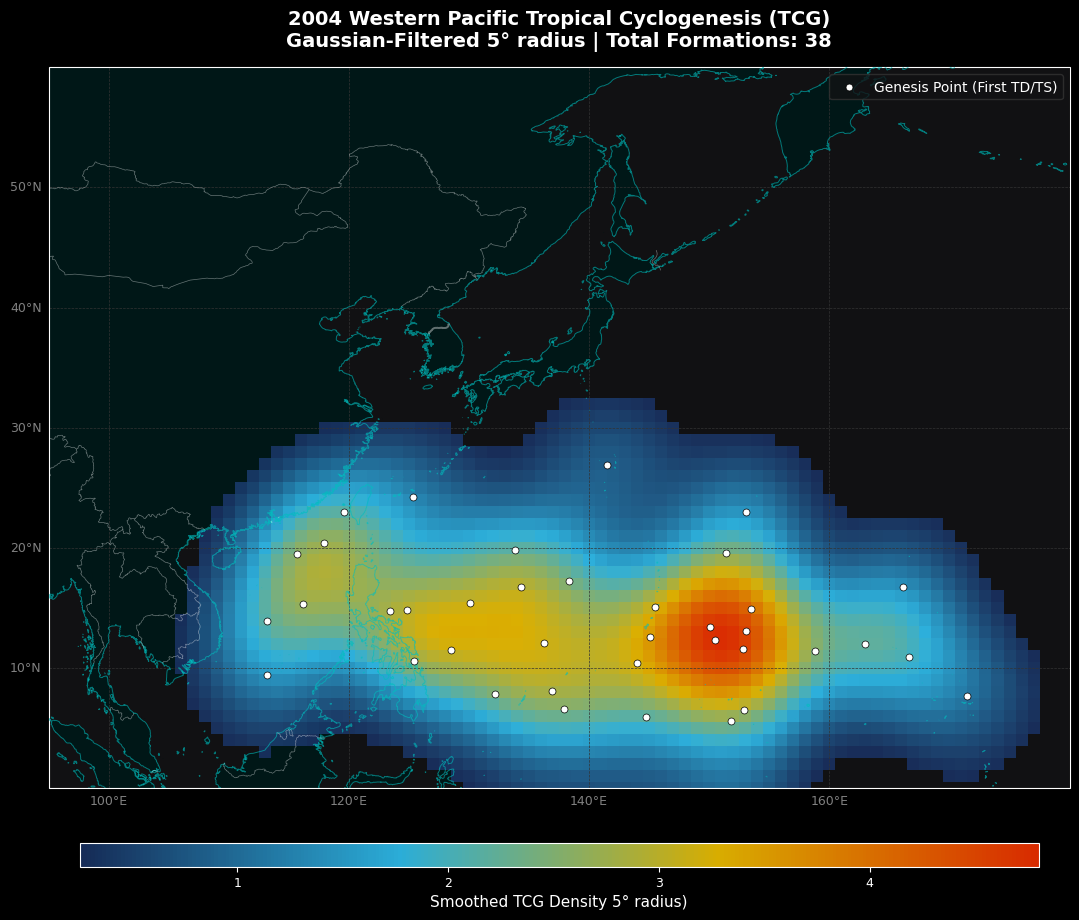

In [29]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import urllib3
from bs4 import BeautifulSoup
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.style as mplstyle
from scipy.ndimage import gaussian_filter  # <-- Added for smoothing

# Setup background style
mplstyle.use("dark_background") 
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
http = urllib3.PoolManager(cert_reqs='CERT_NONE', assert_hostname=False)

def fetch_url(urlLink):
    response = http.request('GET', urlLink)
    return response.data.decode('utf-8')

def parse_data(html_content):
    soup = BeautifulSoup(html_content, 'html.parser')
    return soup.get_text()

# Fetch data
url = "https://gist.githubusercontent.com/hydrangea72/320ed6019712ced9c2ba50c68cde7ae0/raw/0bc8230bc8bd3bc6b88d639fd12b95476b4be950/2004WPAC.txt"
btk_data = fetch_url(url)
parsed_data = parse_data(btk_data)
lines = parsed_data.split('\n')

# Storage arrays for Cyclogenesis points
tcg_lon, tcg_lat = [], []
current_storm_id = None
found_tcg_for_current_storm = False

for line in lines:
    if line.strip():
        stormData = line.split(',')
        storm_id = stormData[1].strip()
        status = stormData[10].strip()

        if storm_id != current_storm_id:
            current_storm_id = storm_id
            found_tcg_for_current_storm = False 

        if not found_tcg_for_current_storm and status in ['TD', 'TS']:
            lon_str = stormData[7].strip()
            lon = (float(lon_str[:-1].strip()) / 10) * -1 if lon_str[-1] == 'W' else float(lon_str[:-1].strip()) / 10
            lat_str = stormData[6].strip()
            lat = (float(lat_str[:-1].strip()) / 10) * -1 if lat_str[-1] == 'S' else float(lat_str[:-1].strip()) / 10

            tcg_lon.append(lon)
            tcg_lat.append(lat)
            found_tcg_for_current_storm = True

# Convert lists to numpy arrays for vector math
points_lon = np.array(tcg_lon)
points_lat = np.array(tcg_lat)

# --- CIRCULAR SLIDING WINDOW CONFIGURATION ---
lon_min, lon_max = 95.0, 180.0
lat_min, lat_max = 0.0, 60.0

# 1. Define a fine pixel grid resolution to slide our window across
fine_res = 1 
fine_x = np.arange(lon_min, lon_max + fine_res, fine_res)
fine_y = np.arange(lat_min, lat_max + fine_res, fine_res)
fine_X, fine_Y = np.meshgrid(fine_x, fine_y)

# 2. Define the circular window radius in degrees (per expert recommendation)
circle_radius = 5

# 3. Slide the circular window over every pixel coordinate
sliding_freq_grid = np.zeros(fine_X.shape)

for i in range(fine_X.shape[0]):
    for j in range(fine_X.shape[1]):
        pixel_lon = fine_X[i, j]
        pixel_lat = fine_Y[i, j]
        
        # Calculate Euclidean distance from this pixel to all storm genesis points
        distances = np.sqrt((points_lon - pixel_lon)**2 + (points_lat - pixel_lat)**2)
        in_circle = distances <= circle_radius
        sliding_freq_grid[i, j] = np.sum(in_circle)

# --- APPLICATION OF GAUSSIAN FILTER ---
# A sigma of 2.0 softens the circular perimeter boundaries perfectly at 0.25 resolution
smoothed_freq = gaussian_filter(sliding_freq_grid, sigma=3.0)

# Mask out areas below a minor count threshold so the edge transitions seamlessly into zero
smoothed_freq = np.ma.masked_where(smoothed_freq < 0.25, smoothed_freq)

# --- PLOTTING ---
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(14, 10))
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

from matplotlib import colors
res = '10m'
ax.add_feature(cfeature.LAND.with_scale(res), facecolor=colors.to_rgba("c", 0.12), zorder=1)
ax.add_feature(cfeature.OCEAN.with_scale(res), facecolor='#111113', zorder=0)
ax.add_feature(cfeature.COASTLINE.with_scale(res), linewidth=0.7, edgecolor="c", alpha=0.6, zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale(res), edgecolor="w", linewidth=0.5, alpha=0.4, zorder=3)

# Seamless color gradient mapping
cmap = mcolors.LinearSegmentedColormap.from_list(
    "tcg_smooth_circular", ["#1a3366", "#33ccff", "#ffcc00", "#ff3300"]
)
cmap.set_bad(alpha=0)

# Render the smoothed moving window frequency counts
mesh = ax.pcolormesh(fine_x, fine_y, smoothed_freq, cmap=cmap, transform=ccrs.PlateCarree(), zorder=2, alpha=0.85, shading='auto')

# Overlay individual genesis points as clear reference dots
ax.scatter(tcg_lon, tcg_lat, color='#ffffff', edgecolor='k', s=25, linewidth=0.5, transform=ccrs.PlateCarree(), zorder=4, label='Genesis Point (First TD/TS)')

# Add Colorbar with forced integers
cbar = plt.colorbar(mesh, ax=ax, orientation='horizontal', pad=0.06, shrink=0.7, aspect=40)
cbar.set_label(f'Smoothed TCG Density {circle_radius}° radius)', fontsize=11, color='w')
cbar.ax.tick_params(labelsize=9, labelcolor='w')
cbar.locator = mticker.MaxNLocator(integer=True)
cbar.update_ticks()

# Gridlines
gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='#333333', zorder=5)
gl.top_labels = False; gl.right_labels = False
gl.xformatter = LONGITUDE_FORMATTER; gl.yformatter = LATITUDE_FORMATTER
gl.xlabel_style = {'color': 'gray', 'size': 9}; gl.ylabel_style = {'color': 'gray', 'size': 9}

plt.legend(loc='upper right', facecolor='#121214', edgecolor='#333333', labelcolor='w')

plt.title(f"2004 Western Pacific Tropical Cyclogenesis (TCG)\nGaussian-Filtered {circle_radius}° radius | Total Formations: {len(tcg_lon)}", 
          fontsize=14, pad=15, weight='bold', color='w')

plt.tight_layout()
plt.show()